# TP2: Algoritmo Genético para diseñar un rover marciano (DEAP)

Este notebook evoluciona el diseño de un rover de seis ruedas con suspensión rocker-bogie mediante un Algoritmo Genético implementado con la librería [DEAP](https://deap.readthedocs.io/en/master/). Cada individuo es un cromosoma de 15 genes reales en [0, 1] que se traducen en las medidas físicas del rover: chasis, balancines y bogies, ruedas, motor, batería y parámetros de manejo. La aptitud, que se **maximiza**, es la distancia media (en metros) que el diseño recorre sobre los terrenos de la generación; las restricciones de la misión se tratan con las reglas de factibilidad de Deb. Al terminar, el mejor diseño se valida en 5 terrenos que no vio durante la evolución.

**Cómo está organizado.** Todo el Algoritmo Genético está escrito en este notebook (secciones 3 y 4): cromosoma, función de aptitud, operadores genéticos y ciclo de generaciones. La carpeta `codigo/` contiene el **simulador**, que funciona como una caja negra: recibe una población de diseños, simula cada rover con física real (MuJoCo) sobre una pista construida con el relieve del cráter Jezero y devuelve cuánto recorrió cada uno y si cumple las restricciones.

## 0) Preparar el ambiente

El notebook tiene dos modos, que se eligen con `RUN_SIMULATION` en la sección 2:

- **Modo resultados** (`RUN_SIMULATION = False`, el valor por defecto): no simula. Carga las corridas del informe guardadas en `logs-corridas/` y muestra sus tablas y gráficos. Funciona en Google Colab con **Entorno de ejecución → Ejecutar todas**: la celda siguiente detecta Colab, clona el repositorio e instala DEAP. Tarda menos de un minuto.
- **Modo simulación** (`RUN_SIMULATION = True`): corre el AG de este notebook con el simulador. En Colab instala MuJoCo automáticamente, pero conviene usar una corrida chica (ver la sección 4). Para la configuración completa, ejecutarlo en una computadora con varios núcleos, desde la carpeta del repositorio:

  ```
  uv sync
  uv run --with jupyterlab jupyter lab TP2_AG_Rover.ipynb
  ```

In [1]:
#@title PREPARAR EL AMBIENTE
import importlib
import importlib.util
import os
import subprocess
import sys

REPO_URL = "https://github.com/RemersaroRamiro/tp2-ag-rover-marciano.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB and not os.path.isdir("logs-corridas"):
    if not os.path.isdir("tp2-ag-rover-marciano"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    os.chdir("tp2-ag-rover-marciano")

if importlib.util.find_spec("deap") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "deap"], check=True)
    importlib.invalidate_caches()

print("Python", sys.version.split()[0], "| Google Colab" if IN_COLAB else "| local", "| carpeta:", os.getcwd())

Python 3.14.3 | local | carpeta: C:\Users\ramib\Desktop\REMERSARO_HQ\UTN\INTELIGENCIA ARTIFICIAL\tp2-ag-rover-marciano


## 1) Importar librerías

numpy, DEAP y matplotlib, más dos módulos livianos del proyecto que no simulan nada: `genome_spec` (la tabla de los 15 genes y su conversión a valores físicos) y `reference_rovers` (el diseño de referencia). El simulador solo se importa en la sección 4 si `RUN_SIMULATION = True`.

In [2]:
#@title IMPORTAR LIBRERÍAS
%matplotlib inline
import csv
import json
import math
import random
from importlib import metadata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from deap import base, creator, tools
from IPython.display import Markdown, display

sys.path.insert(0, str(Path("codigo").resolve()))
import genome_spec
import reference_rovers

print(f"numpy {np.__version__} | DEAP {metadata.version('deap')} | matplotlib {metadata.version('matplotlib')}")

numpy 2.5.4 | DEAP 1.4.4 | matplotlib 3.11.2


## 2) Establecer parámetros generales de la Corrida

Los valores por defecto son los de la **Tabla 1** de la entrega parcial (la corrida base `c1-base`). En Colab se cambian con el formulario de la derecha.

| Parámetro | Qué es | Alternativas |
|---|---|---|
| `POPULATION_SIZE` | individuos (diseños de rover) por generación | |
| `GENERATIONS` | generaciones; la generación 0 es la población inicial | |
| `TERRAINS_PER_GENERATION` | terrenos en los que se simula cada diseño de una generación; la distancia se promedia | |
| `VALIDATION_TERRAINS` | terrenos no vistos durante la evolución, para validar al final | |
| `SEED` | semilla: la población inicial, los operadores y los terrenos derivan de ella | |
| `SELECTION` | método de selección | `"tournament"` (torneo) o `"roulette"` (ruleta) |
| `TOURNAMENT_SIZE` | participantes de cada torneo (k) | |
| `CROSSOVER` | método de cruzamiento | `"blx"` (BLX-α) o `"binomial"` |
| `CROSSOVER_RATE` | probabilidad de cruzar cada pareja seleccionada | |
| `BLX_ALPHA` | α del cruce BLX-α | |
| `BINOMIAL_GENE_RATE` | con cruce binomial, probabilidad de intercambiar cada gen | |
| `MUTATION_GENE_RATE` | probabilidad de mutar cada gen | |
| `SIGMA_MIN`, `SIGMA_MAX` | σ de la mutación gaussiana con la población diversa y con la población convergida | |
| `ADAPTIVE_MUTATION` | si σ se adapta a la diversidad de la población | `False`: σ fija = `SIGMA_MIN` |
| `ELITE_COUNT` | mejores individuos que pasan sin cambios a la generación siguiente | `0`: sin elitismo |
| `RUN_SIMULATION` | modo del notebook | `True`: simula; `False`: carga resultados |
| `WORKERS` | procesos de simulación en paralelo | `None`: uno por núcleo |
| `MAX_SIM_TIME_S` | tope de tiempo simulado por rover, en segundos | `None`: el que se deriva de la pista |
| `RUN_DIR` | corrida del informe que se muestra en modo resultados | las 6 carpetas de `logs-corridas/` |

In [3]:
#@title PARÁMETROS DE LA CORRIDA (Tabla 1 de la entrega parcial)
POPULATION_SIZE = 30  #@param {type:"integer"}
GENERATIONS = 30  #@param {type:"integer"}
TERRAINS_PER_GENERATION = 2  #@param {type:"integer"}
VALIDATION_TERRAINS = 5  #@param {type:"integer"}
SEED = 1  #@param {type:"integer"}

SELECTION = "tournament"  #@param ["tournament", "roulette"]
TOURNAMENT_SIZE = 3  #@param {type:"integer"}

CROSSOVER = "blx"  #@param ["blx", "binomial"]
CROSSOVER_RATE = 0.9  #@param {type:"number"}
BLX_ALPHA = 0.3  #@param {type:"number"}
BINOMIAL_GENE_RATE = 0.5  #@param {type:"number"}

MUTATION_GENE_RATE = 0.1  #@param {type:"number"}
SIGMA_MIN = 0.1  #@param {type:"number"}
SIGMA_MAX = 0.3  #@param {type:"number"}
ADAPTIVE_MUTATION = True  #@param {type:"boolean"}

ELITE_COUNT = 2  #@param {type:"integer"}

RUN_SIMULATION = False  #@param {type:"boolean"}
WORKERS = None
MAX_SIM_TIME_S = None

RUN_DIR = "logs-corridas/c1-base"  #@param ["logs-corridas/c1-base", "logs-corridas/c2-ruleta", "logs-corridas/c3-binomial", "logs-corridas/c4-sigma-fija", "logs-corridas/c5-sin-elite", "logs-corridas/random-search"]
RANDOM_DIR = "logs-corridas/random-search"
EXPERIMENT_DIR = "logs-corridas"

print("Parámetros de la corrida definidos")

Parámetros de la corrida definidos


## 3) Inicializar objetos de DEAP para utilizar

**Cromosoma.** Cada individuo es un `creator.Individual`: una lista de 15 números reales en [0, 1]. Cada gen se traduce en un valor físico dentro de su rango (`genome_spec.decode`); la escala logarítmica se usa en los genes cuyo rango abarca un orden de magnitud. La topología es fija: seis ruedas en una suspensión rocker-bogie simétrica, así que un gen describe los dos lados.

| # | Gen | Qué representa | Rango físico | Unidad | Escala |
|---|---|---|---|---|---|
| 0 | `chassis_length_m` | largo del chasis | 1.5 a 3.5 | m | lineal |
| 1 | `track_width_m` | distancia lateral entre las ruedas izquierdas y derechas | 1.5 a 3 | m | lineal |
| 2 | `chassis_height_m` | alto del chasis | 0.3 a 0.8 | m | lineal |
| 3 | `rocker_pivot_height_m` | altura del pivote del balancín sobre los ejes de las ruedas | 0.4 a 1.2 | m | lineal |
| 4 | `rocker_pivot_offset` | posición del pivote del balancín a lo largo del chasis | -0.3 a 0.3 | fracción del largo | lineal |
| 5 | `rocker_front_arm_m` | brazo del balancín: pivote a rueda delantera | 0.5 a 1.5 | m | lineal |
| 6 | `rocker_rear_arm_m` | brazo del balancín: pivote al pivote del bogie | 0.3 a 1.2 | m | lineal |
| 7 | `bogie_length_m` | largo del bogie: entre ruedas media y trasera | 0.4 a 1.4 | m | lineal |
| 8 | `wheel_diameter_m` | diámetro de las seis ruedas | 0.3 a 0.8 | m | lineal |
| 9 | `wheel_width_m` | ancho de las seis ruedas | 0.1 a 0.5 | m | lineal |
| 10 | `motor_peak_torque_nm` | torque pico del motor de cada rueda | 15 a 150 | N·m | logarítmica |
| 11 | `battery_energy_wh` | energía de la batería | 500 a 4000 | Wh | logarítmica |
| 12 | `target_speed_mps` | velocidad crucero | 0.3 a 1 | m/s | lineal |
| 13 | `torque_limit_fraction` | fracción del torque pico que usa el controlador | 0.3 a 1 | 0 a 1 | lineal |
| 14 | `slope_brake` | cuánto frena el controlador según la pendiente (0 = nunca) | 0 a 1 | 0 a 1 | lineal |

**Población inicial.** Al azar: cada gen de cada individuo se sortea uniforme en [0, 1] a partir de la semilla de la corrida.

**Función de aptitud (se maximiza).** `creator.FitnessMax`, con `weights=(1.0,)`. El simulador devuelve, para cada diseño, la distancia recorrida en cada terreno y cuánto viola las restricciones de la misión (masa, vuelco, tamaño plegado y altura libre). Las reglas de Deb se convierten en un solo número:

- **diseño legal:** aptitud = distancia media recorrida en los terrenos de la generación, en metros (≥ 0);
- **diseño ilegal:** aptitud = −(1 + violación total), siempre negativa. La violación total suma cuánto se pasa de cada límite, en proporción (0,1 = 10 % por encima).

Así un diseño legal siempre supera a uno ilegal, entre legales gana el que llega más lejos y entre ilegales el que menos viola las restricciones, sin pesos que ajustar.

**Operadores genéticos** (registrados en un `base.Toolbox` de DEAP):

| Etapa | Método base | Alternativa |
|---|---|---|
| Selección | torneo, `tools.selTournament(tournsize=3)` | ruleta, `tools.selRoulette` sobre la aptitud desplazada f − min(f) + 10⁻⁶, porque la ruleta necesita aptitudes positivas |
| Cruzamiento (p = 0,9 por pareja) | BLX-α, `tools.cxBlend(alpha=0.3)` | binomial, `tools.cxUniform(indpb=0.5)` |
| Mutación | gaussiana por gen, `tools.mutGaussian(mu=0, sigma=σ, indpb=0.1)` | σ fija |
| Elitismo | los 2 mejores pasan sin cambios (`tools.selBest`) | sin elitismo |

Después del cruce y de la mutación cada gen se **refleja** dentro de [0, 1] (si se pasa por 0,05 de un borde, vuelve 0,05 hacia adentro), para que los genes no se amontonen en los bordes. La **mutación adaptativa** cambia σ según la convergencia: σ_g = σ_min + (σ_max − σ_min) · clip(1 − D_g / D_0, 0, 1), donde D es la diversidad (desvío estándar medio por gen) y D_0 la de la generación 0. Con la población diversa los pasos son chicos; a medida que converge, crecen.

In [4]:
#@title ESTRUCTURA DEL CROMOSOMA Y POBLACIÓN INICIAL
GENOME_LENGTH = genome_spec.GENOME_LENGTH

if not hasattr(creator, "FitnessMax"):
    creator.create("FitnessMax", base.Fitness, weights=(1.0,))
if not hasattr(creator, "Individual"):
    creator.create("Individual", list, fitness=creator.FitnessMax)


def initial_population(rng):
    return rng.uniform(0.0, 1.0, size=(POPULATION_SIZE, GENOME_LENGTH))


def to_individuals(population, fitness):
    individuals = [creator.Individual(float(gene) for gene in row) for row in population]
    for individual, value in zip(individuals, fitness):
        individual.fitness.values = (float(value),)
    return individuals


example_population = initial_population(np.random.default_rng(SEED))
print(f"Aptitud: creator.FitnessMax, pesos {creator.FitnessMax.weights} (se maximiza)")
print(f"Individuo: creator.Individual, lista de {GENOME_LENGTH} genes reales en [0, 1]")
print(f"Población inicial: {len(example_population)} individuos al azar. El primero:")
print(np.round(example_population[0], 3).tolist())

Aptitud: creator.FitnessMax, pesos (1.0,) (se maximiza)
Individuo: creator.Individual, lista de 15 genes reales en [0, 1]
Población inicial: 30 individuos al azar. El primero:
[0.512, 0.95, 0.144, 0.949, 0.312, 0.423, 0.828, 0.409, 0.55, 0.028, 0.754, 0.538, 0.33, 0.788, 0.303]


In [5]:
#@title FUNCIÓN DE APTITUD (REGLAS DE DEB)
INFEASIBLE_OFFSET = 1.0


def fitness_deb(distances_m, total_violation, legal):
    if not all(math.isfinite(d) for d in distances_m) or not math.isfinite(total_violation):
        return -math.inf
    if legal:
        return sum(max(d, 0.0) for d in distances_m) / len(distances_m)
    return -(INFEASIBLE_OFFSET + total_violation)


print("Diseño legal que recorre 120 m y 80 m:", fitness_deb([120.0, 80.0], 0.0, True))
print("Diseño ilegal con 15 % de exceso de masa:", fitness_deb([300.0, 300.0], 0.15, False))

Diseño legal que recorre 120 m y 80 m: 100.0
Diseño ilegal con 15 % de exceso de masa: -1.15


In [6]:
#@title OPERADORES GENÉTICOS
ROULETTE_EPSILON = 1e-6


class RouletteSlot:
    __slots__ = ("individual", "fitness")

    def __init__(self, individual, weight):
        self.individual = individual
        self.fitness = creator.FitnessMax((weight,))


def select_roulette(individuals, k):
    values = np.array([individual.fitness.values[0] for individual in individuals], dtype=float)
    finite = np.isfinite(values)
    if not finite.any():
        return tools.selRandom(individuals, k)
    weights = np.where(finite, values - values[finite].min() + ROULETTE_EPSILON, 0.0)
    wheel = [RouletteSlot(individual, float(weight)) for individual, weight in zip(individuals, weights)]
    chosen = tools.selRoulette(wheel, k)
    while len(chosen) < k:
        chosen += tools.selRoulette(wheel, k - len(chosen))
    return [slot.individual for slot in chosen]


toolbox = base.Toolbox()
if SELECTION == "tournament":
    toolbox.register("select", tools.selTournament, tournsize=TOURNAMENT_SIZE)
else:
    toolbox.register("select", select_roulette)
if CROSSOVER == "blx":
    toolbox.register("mate", tools.cxBlend, alpha=BLX_ALPHA)
else:
    toolbox.register("mate", tools.cxUniform, indpb=BINOMIAL_GENE_RATE)
toolbox.register("mutate", tools.mutGaussian, mu=0.0, sigma=SIGMA_MIN, indpb=MUTATION_GENE_RATE)


def reflect(genes):
    folded = np.mod(np.asarray(genes, dtype=float), 2.0)
    return np.where(folded > 1.0, 2.0 - folded, folded)


def vary(parents, sigma):
    offspring = [toolbox.clone(parent) for parent in parents]
    for first, second in zip(offspring[::2], offspring[1::2]):
        if random.random() < CROSSOVER_RATE:
            toolbox.mate(first, second)
            first[:] = reflect(first).tolist()
            second[:] = reflect(second).tolist()
    for child in offspring:
        toolbox.mutate(child, sigma=sigma)
        child[:] = reflect(child).tolist()
    return offspring


def diversity(population):
    return float(np.std(population, axis=0).mean())


def adaptive_sigma(current_diversity, initial_diversity):
    if not ADAPTIVE_MUTATION:
        return SIGMA_MIN
    if initial_diversity <= 0:
        convergence = 1.0
    else:
        convergence = float(np.clip(1.0 - current_diversity / initial_diversity, 0.0, 1.0))
    return SIGMA_MIN + (SIGMA_MAX - SIGMA_MIN) * convergence


for alias in ("select", "mate", "mutate"):
    operator = getattr(toolbox, alias)
    arguments = ", ".join(f"{key}={value!r}" for key, value in operator.keywords.items())
    print(f"toolbox.{alias} = {operator.func.__name__}({arguments})")
print(f"Elitismo: {ELITE_COUNT} | cruce con p = {CROSSOVER_RATE:g} | mutación adaptativa: {ADAPTIVE_MUTATION}")

toolbox.select = selTournament(tournsize=3)
toolbox.mate = cxBlend(alpha=0.3)
toolbox.mutate = mutGaussian(mu=0.0, sigma=0.1, indpb=0.1)
Elitismo: 2 | cruce con p = 0.9 | mutación adaptativa: True


**Ejemplo de individuo:** el diseño de referencia, de escala similar al Perseverance (Tabla 4 de la entrega parcial), con el valor de cada gen en el cromosoma y su valor físico.

In [7]:
#@title EJEMPLO DE INDIVIDUO: DISEÑO DE REFERENCIA DECODIFICADO
reference_genome = reference_rovers.genome(reference_rovers.PERSEVERANCE_LIKE)
reference_values = genome_spec.decode(reference_genome)
for gene, value in zip(genome_spec.GENES, reference_genome):
    print(f"{gene.name:24} gen {value:5.3f}  ->  {reference_values[gene.name]:.4g}")

chassis_length_m         gen 0.250  ->  2
track_width_m            gen 0.533  ->  2.3
chassis_height_m         gen 0.200  ->  0.4
rocker_pivot_height_m    gen 0.188  ->  0.55
rocker_pivot_offset      gen 0.500  ->  0
rocker_front_arm_m       gen 0.700  ->  1.2
rocker_rear_arm_m        gen 0.556  ->  0.8
bogie_length_m           gen 0.600  ->  1
wheel_diameter_m         gen 0.450  ->  0.525
wheel_width_m            gen 0.750  ->  0.4
motor_peak_torque_nm     gen 0.903  ->  120
battery_energy_wh        gen 0.667  ->  2000
target_speed_mps         gen 0.286  ->  0.5
torque_limit_fraction    gen 0.714  ->  0.8
slope_brake              gen 0.500  ->  0.5


## 4) Ejecutar la corrida del algoritmo mostrando resultados

### Ciclo de una generación

`run_ga` es el ciclo completo del AG. En cada generación:

1. **Evaluación:** se simula toda la población de una vez (`evaluate`) y se calcula la aptitud de cada diseño.
2. **Estadísticas:** máximo, promedio, mediana y desvío de la aptitud; diversidad de la población y el σ de mutación que se va a usar.
3. **Nueva generación** (`next_generation`): los `ELITE_COUNT` mejores pasan sin cambios (elitismo); el resto se elige con `toolbox.select`, se cruza de a pares con probabilidad `CROSSOVER_RATE`, se muta con el σ de la generación y se refleja dentro de [0, 1] (`vary`).

Los individuos de élite se vuelven a evaluar en la generación siguiente, porque cada generación usa terrenos nuevos. La corrida termina al completar `GENERATIONS` generaciones.

In [8]:
#@title CICLO DE GENERACIONES
def next_generation(population, fitness, sigma, rng):
    individuals = to_individuals(population, fitness)
    elites = tools.selBest(individuals, ELITE_COUNT)
    random.seed(int(rng.integers(2**63)))
    parents = toolbox.select(individuals, POPULATION_SIZE - ELITE_COUNT)
    children = vary(parents, sigma)
    return np.array(elites + children, dtype=float)


def run_ga(evaluate, generations, seed, verbose=False):
    rng = np.random.default_rng(seed)
    population = initial_population(rng)
    initial_diversity = None
    history = []
    for generation in range(generations):
        fitness = np.array(evaluate(population), dtype=float)
        fitness = np.where(np.isfinite(fitness), fitness, -np.inf)
        current_diversity = diversity(population)
        if initial_diversity is None:
            initial_diversity = current_diversity
        sigma = adaptive_sigma(current_diversity, initial_diversity)
        finite = fitness[np.isfinite(fitness)]
        best = int(np.argmax(fitness))
        history.append({
            "generation": generation, "population": population.copy(), "fitness": fitness,
            "best": float(fitness[best]), "best_genome": population[best].copy(),
            "mean": float(finite.mean()) if len(finite) else math.nan,
            "median": float(np.median(finite)) if len(finite) else math.nan,
            "std": float(finite.std()) if len(finite) else math.nan,
            "diversity": current_diversity, "mutation_sigma": sigma})
        if verbose:
            record = history[-1]
            print(f"Generación {generation:3d} | máximo {record['best']:8.2f} | promedio {record['mean']:8.2f} | "
                  f"diversidad {current_diversity:.3f} | σ {sigma:.3f}")
        if generation < generations - 1:
            population = next_generation(population, fitness, sigma, rng)
    return history


print("Ciclo del AG definido: run_ga(evaluate, generations, seed)")

Ciclo del AG definido: run_ga(evaluate, generations, seed)


### Comprobación: este AG es el que generó las corridas del informe

Las 6 corridas de `logs-corridas/` se ejecutaron desde la terminal con `codigo/evolve.py`, que usa el AG de `codigo/ga.py`. Esta celda demuestra que el AG escrito en este notebook es el mismo:

- corre `run_ga` y el AG de `codigo/ga.py` con la misma semilla y un evaluador de prueba (una fórmula rápida, sin simulador) y verifica que generan **exactamente** las mismas poblaciones y estadísticas en cada generación;
- recalcula con `fitness_deb` la aptitud de cada diseño validado en las 6 corridas y la compara con la registrada.

In [9]:
#@title COMPROBACIÓN: EL AG DEL NOTEBOOK ES EL DE codigo/ga.py
import ga


def test_evaluate(population):
    distances = 100.0 * population[:, :5].mean(axis=1) + 40.0 * population[:, 5]
    violations = np.maximum(population[:, 0] - 0.8, 0.0)
    return [fitness_deb([d], v, v == 0.0) for d, v in zip(distances, violations)]


TEST_GENERATIONS = 10
notebook_history = run_ga(test_evaluate, TEST_GENERATIONS, SEED)
ga_config = ga.GAConfig(
    population_size=POPULATION_SIZE, elite_count=ELITE_COUNT, selection=SELECTION, tournament_size=TOURNAMENT_SIZE,
    crossover=CROSSOVER, crossover_rate=CROSSOVER_RATE, blx_alpha=BLX_ALPHA, binomial_indpb=BINOMIAL_GENE_RATE,
    mutation_gene_rate=MUTATION_GENE_RATE, mutation_sigma=SIGMA_MIN, sigma_max=SIGMA_MAX,
    adaptive_mutation=ADAPTIVE_MUTATION, seed=SEED)
ga_history = ga.run(lambda population: [ga.Evaluation(f) for f in test_evaluate(population)], ga_config,
                    TEST_GENERATIONS).records
same_ga = len(notebook_history) == len(ga_history) and all(
    np.array_equal(mine["population"], theirs.population)
    and [mine["best"], mine["mean"], mine["median"], mine["std"], mine["diversity"], mine["mutation_sigma"]]
    == [theirs.best_fitness, theirs.mean_fitness, theirs.median_fitness, theirs.std_fitness, theirs.diversity, theirs.sigma]
    for mine, theirs in zip(notebook_history, ga_history))

checked = matching = 0
for manifest_path in sorted(Path("logs-corridas").glob("*/run.json")):
    validation = json.loads(manifest_path.read_text(encoding="utf-8"))["validation"]
    for entry in validation["candidates"] + [validation["reference"]]:
        for distance, recorded in zip(entry["distances_m"], entry["fitness"]):
            checked += 1
            matching += fitness_deb([distance], entry["total_violation"], entry["legal"]) == recorded

print(f"Ciclo del AG, {TEST_GENERATIONS} generaciones con semilla {SEED}:",
      "idéntico a codigo/ga.py" if same_ga else "DISTINTO de codigo/ga.py")
print(f"Función de aptitud contra las corridas del informe: {matching} de {checked} valores coinciden")
if not same_ga or matching != checked:
    raise AssertionError("El AG del notebook no coincide con el que generó las corridas")

Ciclo del AG, 10 generaciones con semilla 1: idéntico a codigo/ga.py
Función de aptitud contra las corridas del informe: 145 de 145 valores coinciden


### Ejecución de la corrida

- **Modo simulación:** corre `run_ga` con el simulador de `codigo/` como función de evaluación. El simulador devuelve, para cada diseño, las distancias recorridas, la violación total y si es legal; la aptitud la calcula `fitness_deb` de este notebook (y se controla que coincida con la de `codigo/fitness.py`). Al final se validan los 3 mejores diseños de la población final y el diseño de referencia en los terrenos de validación. Con la Tabla 1 son 30 × 30 × 2 = 1800 simulaciones: en una computadora de 16 núcleos tardó entre 39 y 48 minutos, y en Colab, con 2 procesadores, llevaría varias horas. Para probarlo en Colab, usar por ejemplo `POPULATION_SIZE = 4`, `GENERATIONS = 2` y `VALIDATION_TERRAINS = 1`.
- **Modo resultados:** carga la corrida elegida en `RUN_DIR`.

In [10]:
#@title FUNCIONES AUXILIARES
END_CAUSES = {
    "finished": "llegó a la meta", "dead:stuck": "atascado", "dead:tipped": "volcó", "dead:energy": "sin energía",
    "dead:out_of_lane": "salió del carril", "dead:timeout": "tiempo agotado", "dead:unstable": "simulación inestable"}
UNITS = {"_m": "m", "_nm": "N·m", "_wh": "Wh", "_mps": "m/s"}


def number(value, spec):
    return "—" if value is None or not math.isfinite(value) else format(value, spec)


def load_run(folder):
    folder = Path(folder)
    manifest = json.loads((folder / "run.json").read_text(encoding="utf-8"))
    with (folder / "generations.csv").open(encoding="utf-8", newline="") as file:
        rows = list(csv.DictReader(file))
    columns = {key: [float(row[key]) if row[key] else math.nan for row in rows] for key in rows[0]}
    return {"name": folder.name, "manifest": manifest, "generations": columns}


def markdown_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    return "\n".join(lines)


def unit(gene_name):
    return next((symbol for suffix, symbol in UNITS.items() if gene_name.endswith(suffix)), "—")


def design_table(genome):
    values = genome_spec.decode(np.asarray(genome, dtype=float))
    rows = [[gene.name, f"{gene_value:.3f}", f"{values[gene.name]:.4g}", unit(gene.name)]
            for gene, gene_value in zip(genome_spec.GENES, genome)]
    return markdown_table(["Gen", "Valor en el cromosoma (0 a 1)", "Valor físico", "Unidad"], rows)


def validation_table(entry):
    rows = [[seed, f"{distance:.1f}", END_CAUSES.get(status, status), "sí" if finished else "no"]
            for seed, distance, status, finished
            in zip(entry["seeds"], entry["distances_m"], entry["statuses"], entry["finished_by_seed"])]
    return markdown_table(["Terreno (semilla)", "Distancia (m)", "Causa de fin", "¿Llegó a la meta?"], rows)


def verdict(flag, required):
    answer = "Sí" if flag["success"] else "No"
    legal = "es legal" if flag["legal"] else "es ilegal"
    return (f"**{answer}**: el diseño `{flag['label']}` {legal} y llegó a la meta en {flag['finished']} de "
            f"{flag['seeds']} terrenos de validación (se piden al menos {required}).")


def methods(manifest):
    if manifest.get("kind") != "ga":
        return ["—", "—", "—", "—"]
    p = manifest["ga"]
    selection = f"torneo (k={p['tournament_size']})" if p["selection"] == "tournament" else "ruleta"
    if p["crossover"] == "blx":
        crossover = f"BLX-α (α={p['blx_alpha']:g}), p={p['crossover_rate']:g}"
    else:
        crossover = f"binomial (p_gen={p['binomial_indpb']:g}), p={p['crossover_rate']:g}"
    if p["adaptive_mutation"]:
        sigma = f"σ {p['mutation_sigma']:g}–{p['sigma_max']:g} adaptativa"
    else:
        sigma = f"σ fija {p['mutation_sigma']:g}"
    return [selection, crossover, f"gaussiana, p_gen={p['mutation_gene_rate']:g}, {sigma}", str(p["elite_count"])]


def run_summary(run):
    manifest, preset = run["manifest"], run["manifest"]["preset"]
    kind = "AG" if manifest.get("kind") == "ga" else "búsqueda aleatoria"
    lines = [f"- **Corrida:** `{run['name']}` ({kind})",
             f"- **Tamaño:** {preset['population']} individuos × {preset['generations']} generaciones, "
             f"{preset['seeds_per_generation']} terrenos por generación, semilla {manifest['run_seed']}"]
    if manifest.get("kind") == "ga":
        selection, crossover, mutation, elitism = methods(manifest)
        lines.append(f"- **Métodos:** selección {selection}; cruce {crossover}; mutación {mutation}; elitismo {elitism}")
    lines.append(f"- **Validación:** {len(manifest['validation']['seeds'])} terrenos no vistos durante la evolución")
    return "\n".join(lines)


def comparison_table(runs):
    rows = []
    for run in runs:
        manifest = run["manifest"]
        best = manifest["validation"]["candidates"][0]
        rows.append([run["name"], "AG" if manifest.get("kind") == "ga" else "búsqueda aleatoria", *methods(manifest),
                     number(manifest["final"]["best_fitness"], ".2f"), number(best["mean_distance_m"], ".1f"),
                     f"{best['finished']}/{len(best['seeds'])}", "sí" if manifest["success"]["best"]["success"] else "no"])
    headers = ["Corrida", "Tipo", "Selección", "Cruce", "Mutación", "Elitismo", "Aptitud del mejor diseño",
               "Distancia media de validación (m)", "Llegadas", "¿Resuelve?"]
    return markdown_table(headers, rows)


print("Funciones auxiliares definidas")

Funciones auxiliares definidas


In [11]:
#@title EJECUCIÓN DE LA CORRIDA
if RUN_SIMULATION:
    if importlib.util.find_spec("mujoco") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco"], check=True)
        importlib.invalidate_caches()
    import evaluate
    import evolve
    import presets

    config = evolve.EvolveConfig(
        preset=presets.Preset("notebook", POPULATION_SIZE, GENERATIONS, "corrida del notebook", TERRAINS_PER_GENERATION),
        seed=SEED, workers=WORKERS, validation_seeds=VALIDATION_TERRAINS,
        eval_config=evaluate.EvalConfig(max_sim_time_s=MAX_SIM_TIME_S))
    schedule = config.schedule()
    with evaluate.Evaluator(workers=WORKERS) as pool:
        simulator = evolve.GenerationEvaluator(pool, schedule, config)

        def evaluate_population(population):
            evaluations = simulator(population)
            fitness = [fitness_deb(e.details["distances_m"], e.details["total_violation"], e.details["legal"])
                       for e in evaluations]
            if fitness != [e.fitness for e in evaluations]:
                raise RuntimeError("La aptitud del notebook no coincide con la de codigo/fitness.py")
            return fitness

        history = run_ga(evaluate_population, GENERATIONS, SEED, verbose=True)
        last = history[-1]
        candidates = evolve.best_designs(last["population"], last["fitness"], 3, "final")
        validation = evolve.validate_designs(pool, config, schedule.validation, candidates)
    ga_parameters = {
        "population_size": POPULATION_SIZE, "selection": SELECTION, "tournament_size": TOURNAMENT_SIZE,
        "crossover": CROSSOVER, "crossover_rate": CROSSOVER_RATE, "blx_alpha": BLX_ALPHA,
        "binomial_indpb": BINOMIAL_GENE_RATE, "mutation_gene_rate": MUTATION_GENE_RATE, "mutation_sigma": SIGMA_MIN,
        "sigma_max": SIGMA_MAX, "adaptive_mutation": ADAPTIVE_MUTATION, "elite_count": ELITE_COUNT}
    run = {
        "name": "corrida del notebook",
        "generations": {key: [record[key] for record in history]
                        for key in ("generation", "best", "mean", "diversity", "mutation_sigma")},
        "manifest": {
            "kind": "ga", "run_seed": SEED, "ga": ga_parameters,
            "preset": {"population": POPULATION_SIZE, "generations": GENERATIONS,
                       "seeds_per_generation": TERRAINS_PER_GENERATION},
            "validation": validation, "success": evolve.success_report(validation),
            "final": {"best_fitness": last["best"]}}}
else:
    print(f"Modo resultados: se carga la corrida {RUN_DIR}")
    run = load_run(RUN_DIR)

display(Markdown(run_summary(run)))

Modo resultados: se carga la corrida logs-corridas/c1-base


- **Corrida:** `c1-base` (AG)
- **Tamaño:** 30 individuos × 30 generaciones, 2 terrenos por generación, semilla 1
- **Métodos:** selección torneo (k=3); cruce BLX-α (α=0.3), p=0.9; mutación gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa; elitismo 2
- **Validación:** 5 terrenos no vistos durante la evolución

### Evolución por generación

Máximo y promedio de la aptitud de cada generación, diversidad de la población (desvío estándar medio por gen) y σ de mutación con el que se generó la generación siguiente. Cada generación se evalúa en terrenos distintos, así que la aptitud se lee como tendencia: el máximo de una generación puede ser menor que el de la anterior.

In [12]:
#@title TABLA POR GENERACIÓN
columns = run["generations"]
rows = [[int(generation), number(best, ".2f"), number(mean, ".2f"), number(spread, ".3f"), number(sigma, ".3f")]
        for generation, best, mean, spread, sigma
        in zip(columns["generation"], columns["best"], columns["mean"], columns["diversity"], columns["mutation_sigma"])]
display(Markdown(markdown_table(["Generación", "Máximo", "Promedio", "Diversidad", "σ de mutación"], rows)))

| Generación | Máximo | Promedio | Diversidad | σ de mutación |
|---|---|---|---|---|
| 0 | 193.79 | 5.60 | 0.278 | 0.100 |
| 1 | 67.46 | 6.35 | 0.245 | 0.124 |
| 2 | 64.61 | 18.02 | 0.197 | 0.159 |
| 3 | 233.35 | 59.83 | 0.152 | 0.191 |
| 4 | 185.93 | 44.40 | 0.139 | 0.200 |
| 5 | 247.68 | 82.11 | 0.118 | 0.215 |
| 6 | 333.87 | 130.79 | 0.106 | 0.224 |
| 7 | 334.97 | 157.09 | 0.117 | 0.216 |
| 8 | 324.10 | 211.70 | 0.109 | 0.222 |
| 9 | 335.89 | 171.16 | 0.109 | 0.222 |
| 10 | 336.25 | 184.56 | 0.126 | 0.209 |
| 11 | 351.21 | 272.75 | 0.114 | 0.218 |
| 12 | 360.67 | 203.34 | 0.108 | 0.222 |
| 13 | 214.70 | 183.01 | 0.114 | 0.218 |
| 14 | 372.45 | 213.60 | 0.094 | 0.232 |
| 15 | 372.46 | 300.36 | 0.104 | 0.225 |
| 16 | 372.46 | 312.63 | 0.101 | 0.227 |
| 17 | 372.46 | 311.72 | 0.101 | 0.228 |
| 18 | 372.46 | 246.40 | 0.110 | 0.221 |
| 19 | 372.46 | 254.34 | 0.105 | 0.224 |
| 20 | 372.46 | 289.56 | 0.114 | 0.218 |
| 21 | 223.21 | 201.95 | 0.112 | 0.220 |
| 22 | 348.35 | 180.51 | 0.097 | 0.230 |
| 23 | 372.46 | 310.76 | 0.090 | 0.235 |
| 24 | 372.46 | 306.14 | 0.093 | 0.233 |
| 25 | 372.47 | 302.59 | 0.081 | 0.242 |
| 26 | 372.46 | 318.05 | 0.090 | 0.235 |
| 27 | 372.46 | 237.15 | 0.087 | 0.238 |
| 28 | 372.46 | 186.01 | 0.096 | 0.231 |
| 29 | 372.46 | 343.31 | 0.089 | 0.236 |

### Mejor diseño obtenido y criterio de éxito

El mejor diseño es el mejor individuo de la población final (`final_best`; en la búsqueda aleatoria, `random_best`). Se valida en los terrenos no vistos y la corrida **resuelve el problema** si ese diseño es legal y llega a la meta en al menos 3 de los 5 terrenos de validación (criterio de la sección 6.3 de la entrega parcial). Como verificación adicional se informan las llegadas de los 3 mejores diseños.

In [13]:
#@title MEJOR DISEÑO, VALIDACIÓN Y CRITERIO DE ÉXITO
validation, success = run["manifest"]["validation"], run["manifest"]["success"]
best = validation["candidates"][0]
print(f"Mejor diseño: {best['label']} | aptitud de entrenamiento {best['training_fitness']:.2f}")
display(Markdown(design_table(best["genome"])))
display(Markdown(validation_table(best)))
display(Markdown("¿Resuelve el problema? " + verdict(success["best"], success["required_finishes"])))
display(Markdown("Top-3 validados, llegadas: "
                 + ", ".join(f"{flag['label']} {flag['finished']}/{flag['seeds']}" for flag in success["top3"])))

Mejor diseño: final_best | aptitud de entrenamiento 372.46


| Gen | Valor en el cromosoma (0 a 1) | Valor físico | Unidad |
|---|---|---|---|
| chassis_length_m | 0.332 | 2.164 | m |
| track_width_m | 0.260 | 1.89 | m |
| chassis_height_m | 0.360 | 0.4799 | m |
| rocker_pivot_height_m | 0.091 | 0.473 | m |
| rocker_pivot_offset | 0.249 | -0.1505 | — |
| rocker_front_arm_m | 0.476 | 0.976 | m |
| rocker_rear_arm_m | 0.189 | 0.4701 | m |
| bogie_length_m | 0.643 | 1.043 | m |
| wheel_diameter_m | 0.614 | 0.6069 | m |
| wheel_width_m | 0.282 | 0.2127 | m |
| motor_peak_torque_nm | 0.992 | 147.2 | N·m |
| battery_energy_wh | 0.213 | 778.6 | Wh |
| target_speed_mps | 0.963 | 0.974 | m/s |
| torque_limit_fraction | 0.871 | 0.9095 | — |
| slope_brake | 0.109 | 0.1095 | — |

| Terreno (semilla) | Distancia (m) | Causa de fin | ¿Llegó a la meta? |
|---|---|---|---|
| 1302828960 | 372.5 | llegó a la meta | sí |
| 899894886 | 372.5 | llegó a la meta | sí |
| 1371778638 | 372.5 | llegó a la meta | sí |
| 1512735633 | 92.0 | atascado | no |
| 1692859205 | 296.7 | atascado | no |

¿Resuelve el problema? **Sí**: el diseño `final_best` es legal y llegó a la meta en 3 de 5 terrenos de validación (se piden al menos 3).

Top-3 validados, llegadas: final_best 3/5, final_2 3/5, final_3 3/5

### Diseño de referencia y búsqueda aleatoria (líneas de base)

El diseño de referencia (tipo Perseverance) se valida en los mismos terrenos que el mejor diseño. La búsqueda aleatoria prueba diseños al azar con el mismo presupuesto de simulaciones que el AG: si el AG no la supera, no está aprendiendo nada.

In [14]:
#@title LÍNEAS DE BASE: DISEÑO DE REFERENCIA Y BÚSQUEDA ALEATORIA
display(Markdown(validation_table(validation["reference"])))
display(Markdown("Diseño de referencia (tipo Perseverance): " + verdict(success["reference"], success["required_finishes"])))
display(Markdown(comparison_table([run, load_run(RANDOM_DIR)])))

| Terreno (semilla) | Distancia (m) | Causa de fin | ¿Llegó a la meta? |
|---|---|---|---|
| 1302828960 | 343.6 | atascado | no |
| 899894886 | 324.3 | atascado | no |
| 1371778638 | 49.3 | atascado | no |
| 1512735633 | 42.1 | atascado | no |
| 1692859205 | 36.4 | atascado | no |

Diseño de referencia (tipo Perseverance): **No**: el diseño `reference` es legal y llegó a la meta en 0 de 5 terrenos de validación (se piden al menos 3).

| Corrida | Tipo | Selección | Cruce | Mutación | Elitismo | Aptitud del mejor diseño | Distancia media de validación (m) | Llegadas | ¿Resuelve? |
|---|---|---|---|---|---|---|---|---|---|
| c1-base | AG | torneo (k=3) | BLX-α (α=0.3), p=0.9 | gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa | 2 | 372.46 | 301.2 | 3/5 | sí |
| random-search | búsqueda aleatoria | — | — | — | — | 364.50 | 290.9 | 1/5 | no |

## 5) Generar gráficos de la corrida

Aptitud máxima y promedio por generación, y diversidad de la población junto con el σ de mutación. Al final, la curva del máximo de las 6 corridas del informe en un mismo gráfico, con su tabla comparativa.

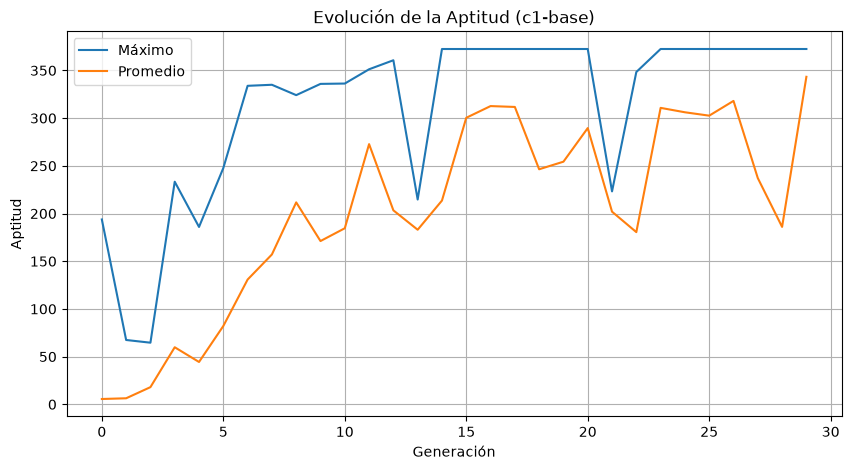

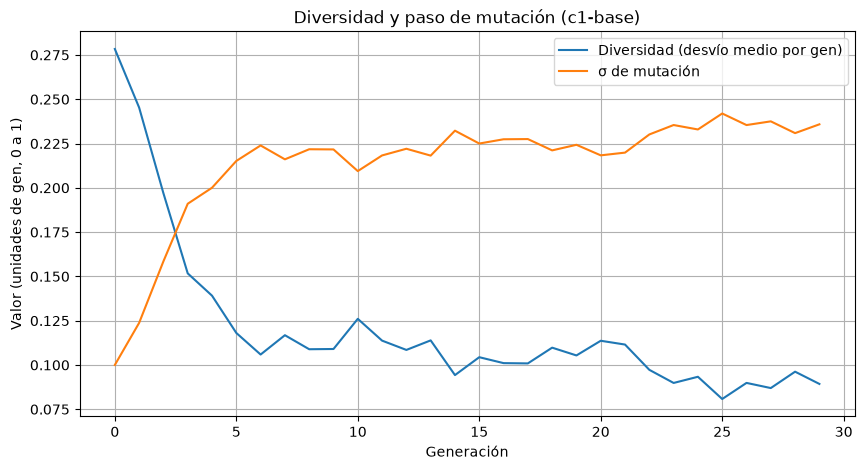

In [15]:
#@title MOSTRAR GRÁFICOS DE LA CORRIDA
columns = run["generations"]

plt.figure(figsize=(10, 5))
plt.plot(columns["generation"], columns["best"], label="Máximo")
plt.plot(columns["generation"], columns["mean"], label="Promedio")
plt.title(f"Evolución de la Aptitud ({run['name']})")
plt.xlabel("Generación")
plt.ylabel("Aptitud")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(columns["generation"], columns["diversity"], label="Diversidad (desvío medio por gen)")
plt.plot(columns["generation"], columns["mutation_sigma"], label="σ de mutación")
plt.title(f"Diversidad y paso de mutación ({run['name']})")
plt.xlabel("Generación")
plt.ylabel("Valor (unidades de gen, 0 a 1)")
plt.grid(True)
plt.legend()
plt.show()

| Corrida | Tipo | Selección | Cruce | Mutación | Elitismo | Aptitud del mejor diseño | Distancia media de validación (m) | Llegadas | ¿Resuelve? |
|---|---|---|---|---|---|---|---|---|---|
| c1-base | AG | torneo (k=3) | BLX-α (α=0.3), p=0.9 | gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa | 2 | 372.46 | 301.2 | 3/5 | sí |
| c2-ruleta | AG | ruleta | BLX-α (α=0.3), p=0.9 | gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa | 2 | 372.46 | 315.6 | 3/5 | sí |
| c3-binomial | AG | torneo (k=3) | binomial (p_gen=0.5), p=0.9 | gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa | 2 | 372.46 | 372.5 | 5/5 | sí |
| c4-sigma-fija | AG | torneo (k=3) | BLX-α (α=0.3), p=0.9 | gaussiana, p_gen=0.1, σ fija 0.1 | 2 | 372.46 | 306.2 | 3/5 | sí |
| c5-sin-elite | AG | torneo (k=3) | BLX-α (α=0.3), p=0.9 | gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa | 0 | 372.46 | 357.3 | 4/5 | sí |
| random-search | búsqueda aleatoria | — | — | — | — | 364.50 | 290.9 | 1/5 | no |

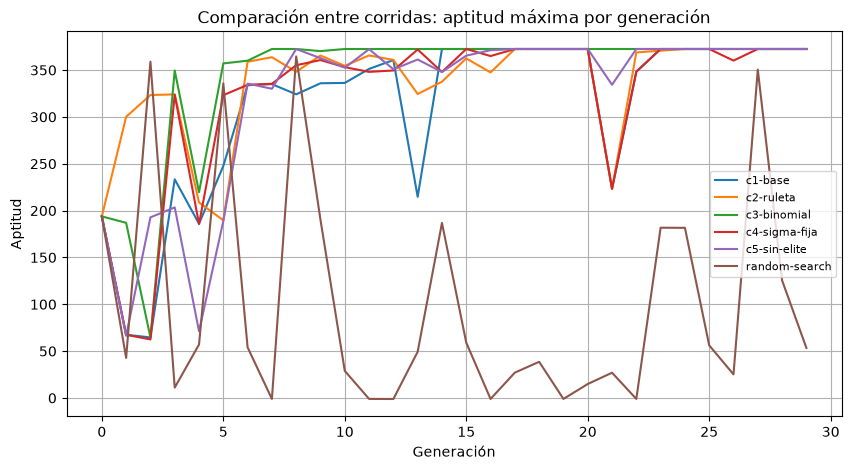

In [16]:
#@title COMPARACIÓN ENTRE CORRIDAS
experiment = [load_run(path.parent) for path in sorted(Path(EXPERIMENT_DIR).glob("*/run.json"))]
display(Markdown(comparison_table(experiment)))

plt.figure(figsize=(10, 5))
for other in experiment:
    plt.plot(other["generations"]["generation"], other["generations"]["best"], label=other["name"])
plt.title("Comparación entre corridas: aptitud máxima por generación")
plt.xlabel("Generación")
plt.ylabel("Aptitud")
plt.grid(True)
plt.legend(fontsize=8)
plt.show()